# Relaxed layouts: diagrams that find their own shape

A reduced diagram (a normal form) has no positions of its own: `reduce_gpf` lays it out in two columns, Z-spiders on the left and X-spiders on the right, which shows the form but not the structure. Here no coordinates are given at all. The diagram is treated like a molecule: its edges are the bonds, and the layout is where an energy is lowest (`relax_layout`, with `networkx`, `pip install zxqec[layout]`):

* `'kamada-kawai'` (default): a spring between every pair of spiders, whose rest length is their distance in the diagram, and the total energy minimised. Spiders close in the diagram end up close in space.
* `'spring'`: a force simulation in which edges pull and all spiders push each other apart.

The start is random but seeded, so every picture here comes out the same each time. Each connected part is relaxed on its own and the parts are set side by side. The positions mean nothing beyond the connectivity: they are not space or time. `draw_relaxed` draws in 2D with PyZX's own `draw_matplotlib`, `draw_relaxed_3d` in 3D (turn it with the mouse in a window).

In [1]:
import pyzx as zx
from zxqec.qprogram import program_from_stim
from zxqec.gpf import reduce_gpf, phases_modulo
from zxqec.spacetime import draw_relaxed, draw_relaxed_3d
import interactive_fold_h_3d as fth          # picks a window backend when imported ...
%matplotlib inline

p = program_from_stim(open('circuits/cultivation/d3_cultivation.stim').read())[0]

def reduced(g):
    """The normal form of g, outcomes written modulo its detectors."""
    res = reduce_gpf(g)
    return phases_modulo(res.to_graph(), res.detectors)

first_checks = reduced(p.stage_graph(0, classical=False))
double_check = reduced(p.stages_graph(3, 4, classical=False))

## The first checks of d = 3 cultivation

The first stage prepares the Steane code. As reduced, in two columns:

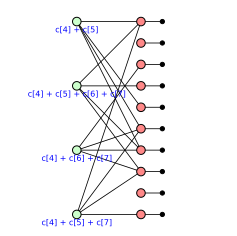

In [2]:
zx.draw_matplotlib(first_checks, figsize=(4, 4))

Relaxed: each of the four Z-spiders (green; a stabilizer of the prepared state, with its outcome parity as its phase) is wired to four qubits and sits among them, and spiders that share qubits pull together into a compact, symmetric shape. The two small parts on the right are qubits not linked to the others.

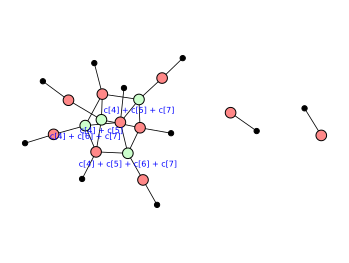

In [3]:
draw_relaxed(first_checks, figsize=(6, 4.5))

## The double-check

The double-check's normal form, 45 spiders: the parity spiders in the middle and the 7π/4 and π/4 gadgets around them. In 2D the core is crowded; in 3D there is room, and in a window it can be turned.

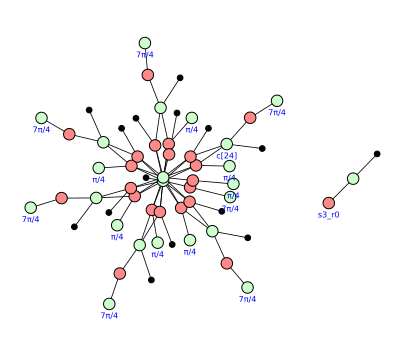

In [4]:
draw_relaxed(double_check, figsize=(7, 6))

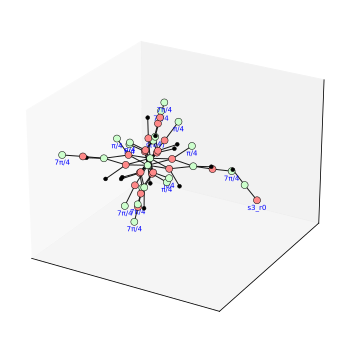

In [5]:
draw_relaxed_3d(double_check, figsize=(7, 6), spider_size=50)

## The whole fold-transversal Hadamard

The method needs nothing but the edges, so it works on any diagram. Here is the whole circuit, 311 spiders, under both energies (half a second each). The force simulation lays it out in sheets: the shape of the program in space and time comes back from its connectivity alone.

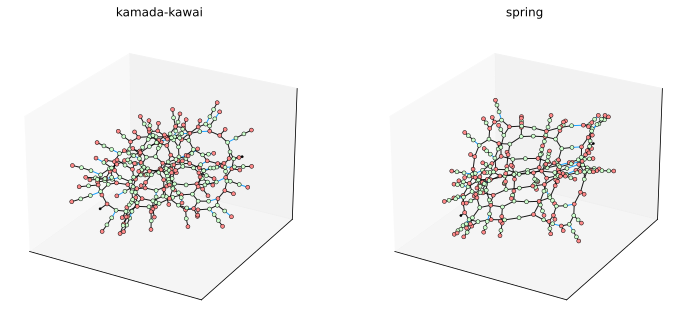

In [6]:
import matplotlib.pyplot as plt
g = fth.build_program().quantum_graph()
fig = plt.figure(figsize=(12, 5.5))
for i, method in enumerate(('kamada-kawai', 'spring')):
    ax = fig.add_subplot(1, 2, i + 1, projection='3d')
    draw_relaxed_3d(g, method=method, ax=ax, show_phases=False, spider_size=16)
    ax.set_title(method)
fig

## What this is not

* **Not space or time.** The positions only reflect which spiders are connected; for space and time use `draw_program_3d` or `draw_level_3d`.
* **A local minimum.** The energy is minimised from a seeded random start; another seed can give another layout (a mirror image, or a different local minimum).
* **Not for very large diagrams.** Kamada-Kawai uses the distance between every pair of spiders, so its cost grows with the square of their number; a few hundred spiders take under a second.